# Marketing Campaign Effectiveness Analysis

**Author:** Bibek Sapkota

## Objective
Evaluate marketing campaign effectiveness through data cleaning, transformation, exploratory data analysis (EDA), visualization, and actionable business insights.::


## 1. Data Collection and Exploration

In [10]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/superstore_data.csv")

print("Rows:", f"{df.shape[0]:,}")
print("Columns:", f"{df.shape[1]:,}")
display(df.head())


Rows: 2,240
Columns: 22


,Id,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain
0,1826,1970,Graduation,Divorced,84835.0,0,0,6/16/2014,0,189,104,379,111,189,218,1,4,4,6,1,1,0
1,1,1961,Graduation,Single,57091.0,0,0,6/15/2014,0,464,5,64,7,0,37,1,7,3,7,5,1,0
2,10476,1958,Graduation,Married,67267.0,0,1,5/13/2014,0,134,11,59,15,2,30,1,3,2,5,2,0,0
3,1386,1967,Graduation,Together,32474.0,1,1,11/5/2014,0,10,0,1,0,0,0,1,1,0,2,7,0,0
4,5371,1989,Graduation,Single,21474.0,1,0,8/4/2014,0,6,16,24,11,0,34,2,3,1,2,7,1,0


In [11]:
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing"))

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["Id"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

,Missing
Income,24
Id,0
Year_Birth,0
Education,0
Marital_Status,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0



Duplicate rows: 0
Duplicate IDs: 0


In [12]:
display(df.describe(include="all").T)

print("\nEducation:")
display(df["Education"].value_counts(dropna=False))

print("\nMarital status:")
display(df["Marital_Status"].value_counts(dropna=False))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,2240.0,NaN,NaN,NaN,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,NaN,NaN,NaN,1968.805804,11.984069,1893.0,1959.0,1970.0,1977.0,1996.0
Education,2240,5,Graduation,1127,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_Status,2240,8,Married,864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Income,2216.0,NaN,NaN,NaN,52247.251354,25173.076661,1730.0,35303.0,51381.5,68522.0,666666.0
Kidhome,2240.0,NaN,NaN,NaN,0.444196,0.538398,0.0,0.0,0.0,1.0,2.0
Teenhome,2240.0,NaN,NaN,NaN,0.50625,0.544538,0.0,0.0,0.0,1.0,2.0
Dt_Customer,2240,663,8/31/2012,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Recency,2240.0,NaN,NaN,NaN,49.109375,28.962453,0.0,24.0,49.0,74.0,99.0
MntWines,2240.0,NaN,NaN,NaN,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0



Education:


,count
Education,
Graduation,1127
PhD,486
Master,370
2n Cycle,203
Basic,54



Marital status:


,count
Marital_Status,
Married,864
Together,580
Single,480
Divorced,232
Widow,77
Alone,3
YOLO,2
Absurd,2


### Initial exploration findings
- 2,240 customer records and 22 original variables.
- `Income` contains 24 missing values.
- No duplicate rows or duplicate customer IDs were found.
- Income contains extreme high values that need treatment.
- `Response` is the campaign response target: 0 = no response, 1 = responded.


## 2. Data Cleaning and Transformation

In [13]:
df_clean = df.copy()

  #Datetime and categorical cleaning
df_clean["Dt_Customer"] = pd.to_datetime(df_clean["Dt_Customer"], errors="coerce")
df_clean["Education"] = df_clean["Education"].astype("string").str.strip()
df_clean["Marital_Status"] = df_clean["Marital_Status"].astype("string").str.strip()

# Missing income: median imputation
missing_income = df_clean["Income"].isna().sum()
income_median = df_clean["Income"].median()
df_clean["Income"] = df_clean["Income"].fillna(income_median)

# IQR outlier detection and treatment
Q1 = df_clean["Income"].quantile(0.25)
Q3 = df_clean["Income"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
income_outliers = (df_clean["Income"] > upper_bound).sum()
df_clean["Income"] = df_clean["Income"].clip(lower=lower_bound, upper=upper_bound)

# Age feature; dataset reference period is approximately 2014
df_clean["Age"] = 2026 - df_clean["Year_Birth"]
valid_age = df_clean["Age"].between(18, 100)
invalid_ages = (~valid_age).sum()
age_median = df_clean.loc[valid_age, "Age"].median()
df_clean.loc[~valid_age, "Age"] = age_median

# Business features
spend_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
purchase_cols = ["NumWebPurchases","NumCatalogPurchases","NumStorePurchases"]

df_clean["Total_Spend"] = df_clean[spend_cols].sum(axis=1)
df_clean["Total_Purchases"] = df_clean[purchase_cols].sum(axis=1)
df_clean["Total_Kids"] = df_clean["Kidhome"] + df_clean["Teenhome"]
df_clean["Customer_Year"] = df_clean["Dt_Customer"].dt.year
df_clean["Response_Label"] = df_clean["Response"].map({0:"No Response", 1:"Responded"})

print("Missing income values imputed:", missing_income)
print("Income outliers treated:", income_outliers)
print("Implausible ages corrected:", invalid_ages)
print("Remaining missing values:", df_clean.isna().sum().sum())



Missing income values imputed: 24
Income outliers treated: 8
Implausible ages corrected: 3
Remaining missing values: 0


In [14]:
# Categorical encoding and numerical scaling
categorical_cols = ["Education", "Marital_Status"]
numerical_cols = ["Income", "Age", "Total_Spend", "Total_Purchases", "Recency", "NumWebVisitsMonth"]

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = encoder.fit_transform(df_clean[categorical_cols])
encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(categorical_cols))

scaler = StandardScaler()
scaled = scaler.fit_transform(df_clean[numerical_cols])
scaled_df = pd.DataFrame(scaled, columns=numerical_cols)

print("Encoded categorical data shape:", encoded_df.shape)
print("Scaled numerical data shape:", scaled_df.shape)
display(encoded_df.head())
display(scaled_df.head())


Encoded categorical data shape: (2240, 13)
Scaled numerical data shape: (2240, 6)


,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


,Income,Age,Total_Spend,Total_Purchases,Recency,NumWebVisitsMonth
0,1.575101,-0.093818,0.970250,0.203070,-1.696001,-1.779198
1,0.249631,0.675970,-0.047828,0.619498,-1.696001,-0.130463
2,0.735789,0.932566,-0.589253,-0.352166,-1.696001,-1.367014
3,-0.926448,0.162778,-0.987848,-1.323831,-1.696001,0.693904
4,-1.451973,-1.718926,-0.854983,-0.907403,-1.696001,0.693904


## 3. Exploratory Data Analysis

### 3.1 Overall campaign response

Overall campaign response rate: 14.91%


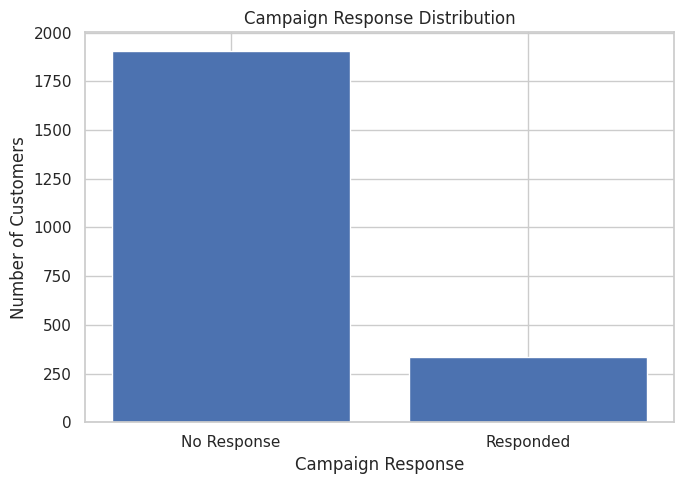

In [15]:
response_rate = df_clean["Response"].mean()
print(f"Overall campaign response rate: {response_rate:.2%}")

counts = df_clean["Response_Label"].value_counts().reindex(["No Response", "Responded"])
plt.figure(figsize=(7,5))
plt.bar(counts.index, counts.values)
plt.title("Campaign Response Distribution")
plt.xlabel("Campaign Response")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


### 3.2 Response by education

,Customers,Response_Rate
Education,,
PhD,486,20.781893
Master,370,15.405405
Graduation,1127,13.487134
2n Cycle,203,10.837438
Basic,54,3.703704


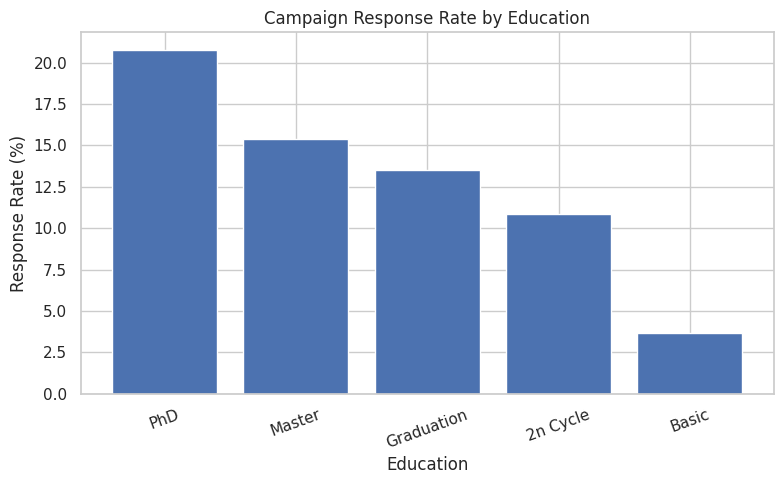

In [16]:
education_response = df_clean.groupby("Education")["Response"].agg(
    Customers="count", Response_Rate="mean"
).sort_values("Response_Rate", ascending=False)
education_response["Response_Rate"] *= 100
display(education_response)

plot_df = education_response.reset_index()
plt.figure(figsize=(8,5))
plt.bar(plot_df["Education"], plot_df["Response_Rate"])
plt.title("Campaign Response Rate by Education")
plt.xlabel("Education")
plt.ylabel("Response Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### 3.3 Response by marital status

,Customers,Response_Rate
Marital_Status,,
Absurd,2,50.000000
YOLO,2,50.000000
Alone,3,33.333333
Widow,77,24.675325
Single,480,22.083333
Divorced,232,20.689655
Married,864,11.342593
Together,580,10.344828


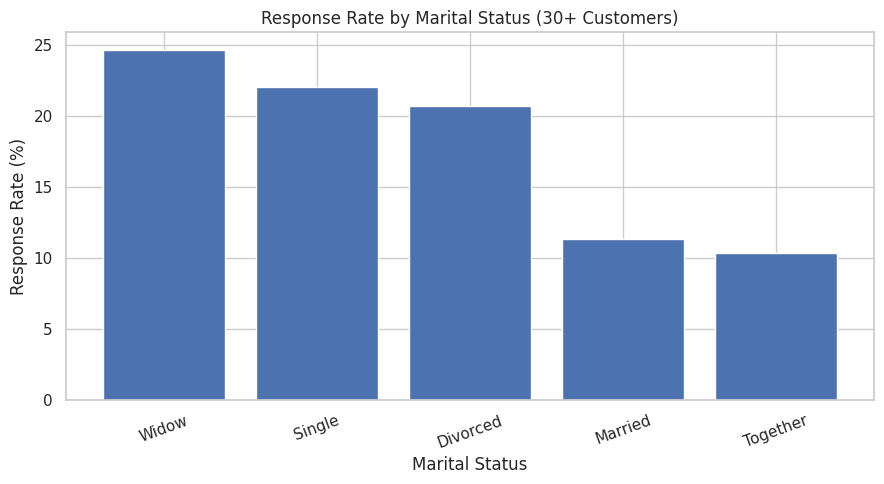

In [17]:
marital_response = df_clean.groupby("Marital_Status")["Response"].agg(
    Customers="count", Response_Rate="mean"
).sort_values("Response_Rate", ascending=False)
marital_response["Response_Rate"] *= 100
display(marital_response)

plot_df = marital_response[marital_response["Customers"] >= 30].reset_index()
plt.figure(figsize=(9,5))
plt.bar(plot_df["Marital_Status"], plot_df["Response_Rate"])
plt.title("Response Rate by Marital Status (30+ Customers)")
plt.xlabel("Marital Status")
plt.ylabel("Response Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### 3.4 Spending and purchase behavior

,Total_Spend,Total_Purchases,Income,NumWebVisitsMonth,Recency
Response_Label,,,,,
No Response,538.93,12.04,50408.37,5.32,51.51
Responded,987.39,15.37,60183.24,5.29,35.38


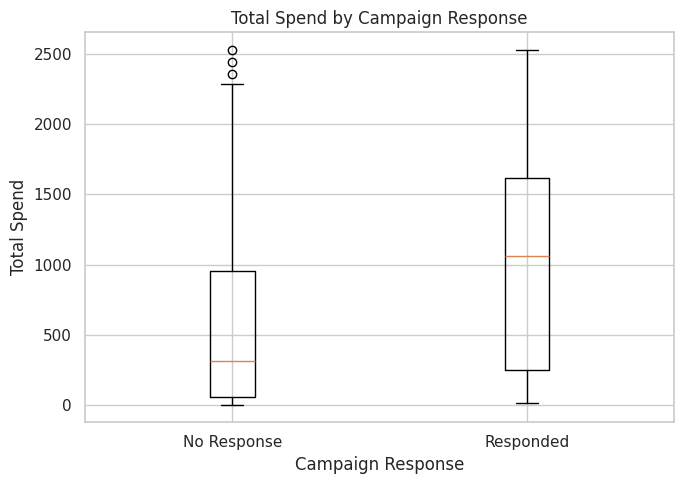

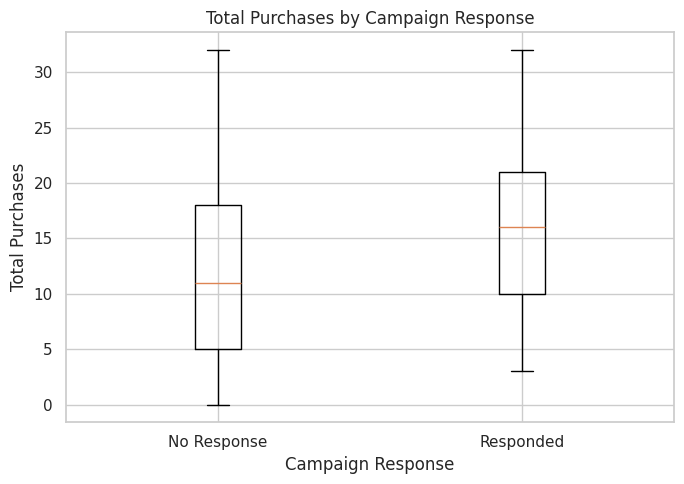

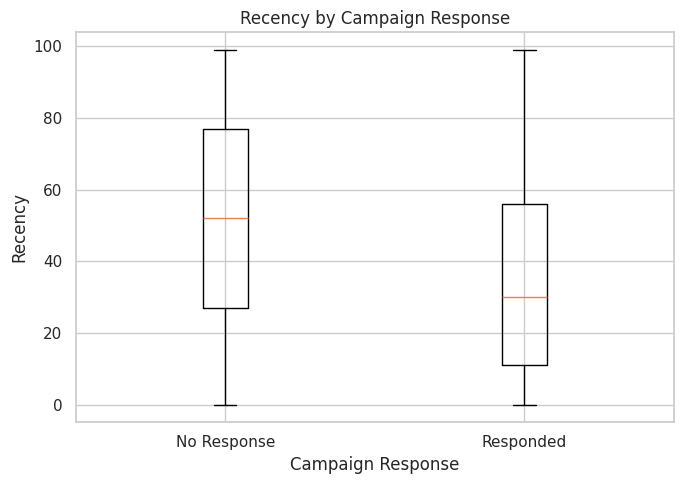

In [18]:
performance = df_clean.groupby("Response_Label")[
    ["Total_Spend","Total_Purchases","Income","NumWebVisitsMonth","Recency"]
].mean().round(2)
display(performance)

for metric in ["Total_Spend", "Total_Purchases", "Recency"]:
    groups = [
        df_clean.loc[df_clean["Response_Label"] == "No Response", metric].dropna(),
        df_clean.loc[df_clean["Response_Label"] == "Responded", metric].dropna()
    ]
    plt.figure(figsize=(7,5))
    plt.boxplot(groups, tick_labels=["No Response", "Responded"])
    plt.title(f"{metric.replace('_',' ')} by Campaign Response")
    plt.xlabel("Campaign Response")
    plt.ylabel(metric.replace("_"," "))
    plt.tight_layout()
    plt.show()


### 3.5 Response over time
The dataset has no campaign launch date. `Dt_Customer` is therefore used only as a **customer enrollment-year cohort**, not as a campaign date.

,Customers,Response_Rate
Dt_Customer,,
2012,494,26.720648
2013,1189,12.952061
2014,557,8.617594


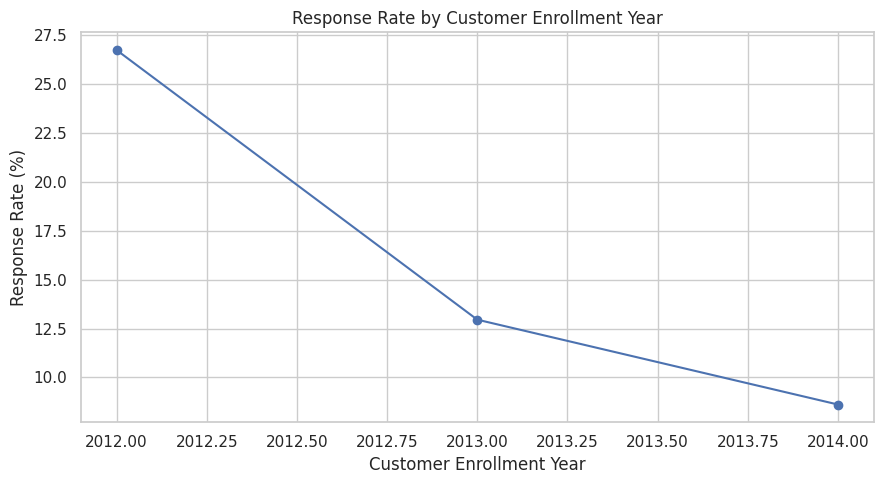

In [19]:
year_response = df_clean.groupby(df_clean["Dt_Customer"].dt.year)["Response"].agg(
    Customers="count", Response_Rate="mean"
)
year_response["Response_Rate"] *= 100
display(year_response)

plt.figure(figsize=(9,5))
plt.plot(year_response.index, year_response["Response_Rate"], marker="o")
plt.title("Response Rate by Customer Enrollment Year")
plt.xlabel("Customer Enrollment Year")
plt.ylabel("Response Rate (%)")
plt.tight_layout()
plt.show()


### 3.6 Correlation heatmap

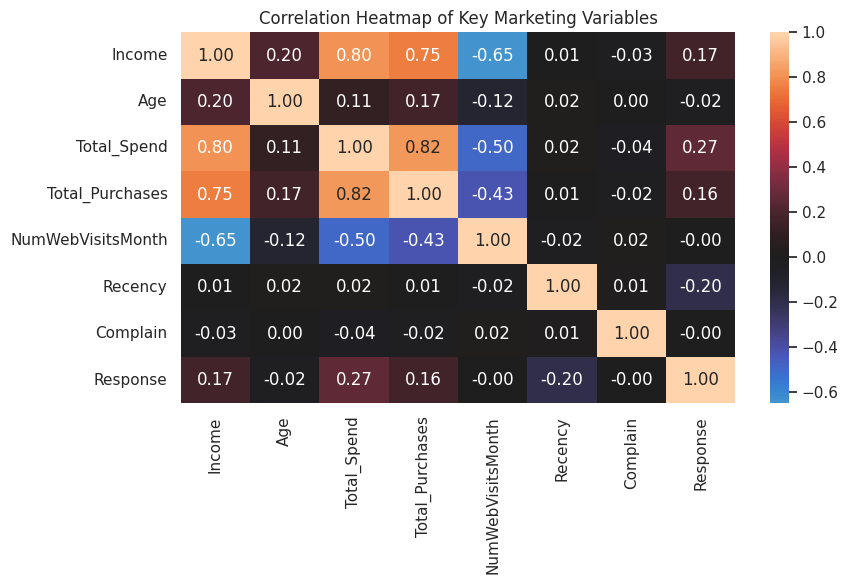

,Correlation with Response
Total_Spend,0.265298
Income,0.166341
Total_Purchases,0.164688
Complain,-0.001707
NumWebVisitsMonth,-0.003987
Age,-0.018369
Recency,-0.198437


In [20]:
corr_cols = ["Income","Age","Total_Spend","Total_Purchases",
              "NumWebVisitsMonth","Recency","Complain","Response"]
corr_matrix = df_clean[corr_cols].corr()

plt.figure(figsize=(9,6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", center=0)
plt.title("Correlation Heatmap of Key Marketing Variables")
plt.tight_layout()
plt.show()

display(corr_matrix["Response"].drop("Response").sort_values(ascending=False).to_frame(
    "Correlation with Response"
))


### 3.7 Top and underperforming segments

,Customers,Response_Rate,Avg_Spend,Avg_Purchases
Education,,,,
PhD,486,20.781893,672.409465,13.454733
Master,370,15.405405,611.781081,12.500000
Graduation,1127,13.487134,619.898846,12.680568
2n Cycle,203,10.837438,496.527094,11.556650
Basic,54,3.703704,81.796296,5.222222


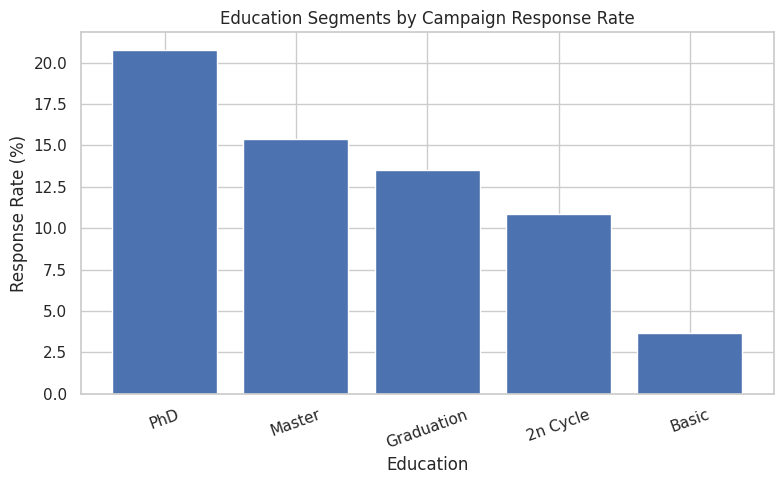

In [21]:
segment = df_clean.groupby("Education").agg(
    Customers=("Id","count"),
    Response_Rate=("Response","mean"),
    Avg_Spend=("Total_Spend","mean"),
    Avg_Purchases=("Total_Purchases","mean")
).sort_values("Response_Rate", ascending=False)

segment["Response_Rate"] *= 100
display(segment)

plt.figure(figsize=(8,5))
plt.bar(segment.index, segment["Response_Rate"])
plt.title("Education Segments by Campaign Response Rate")
plt.xlabel("Education")
plt.ylabel("Response Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 4. Key Insights and Recommendations

### Key Insights
1. The overall campaign response rate is approximately **14.9%**.
2. Responders have substantially higher average total spending than non-responders.
3. Responders also have higher total purchase activity.
4. Responders have lower average recency, indicating that recently active customers are more responsive.
5. Among major education groups, PhD customers show the highest response rate, while Basic customers show the lowest.
6. Total spending has a stronger positive relationship with response than income.
7. Monthly web visits have almost no linear relationship with response in this dataset.
8. Tiny categories such as `Absurd`, `YOLO`, and `Alone` should not be used for strategic conclusions because their sample sizes are extremely small.
9. True campaign/channel ROI cannot be calculated because campaign budget, channel, impressions, clicks, conversions, and revenue are unavailable.

### Business Recommendations
- Prioritize recently active customers in future campaigns.
- Create high-value segments using total spending and purchase frequency.
- Personalize offers using actual customer behavior instead of relying on income alone.
- Test differentiated messaging for meaningful customer segments.
- Track campaign ID, channel, budget, impressions, clicks, conversions, revenue, and campaign dates in future data collection.
- Use those fields to calculate CTR, conversion rate, CPA, ROAS, and ROI.


## 5. Documentation of Data Quality

In [22]:
quality_summary = pd.DataFrame({
    "Issue": [
        "Missing Income", "Income Outliers", "Implausible Ages",
        "Duplicate Rows", "Duplicate IDs"
    ],
    "Treatment": [
        f"Median imputation ({missing_income} values)",
        f"IQR upper-bound capping ({income_outliers} observations)",
        f"Median replacement ({invalid_ages} observations)",
        "None found",
        "None found"
    ]
})
display(quality_summary)


,Issue,Treatment
0,Missing Income,Median imputation (24 values)
1,Income Outliers,IQR upper-bound capping (8 observations)
2,Implausible Ages,Median replacement (3 observations)
3,Duplicate Rows,None found
4,Duplicate IDs,None found


## 6. Save Cleaned Dataset

In [23]:
OUTPUT_PATH = Path("../data/marketing_campaign_cleaned.csv")
df_clean.to_csv(OUTPUT_PATH, index=False)
print("Saved:", OUTPUT_PATH)
print("Final shape:", df_clean.shape)


OSError: Cannot save file into a non-existent directory: '../data'

## 7. Conclusion

The campaign response rate is relatively low, so broad untargeted marketing leaves substantial room for improvement. The analysis indicates that **recency, spending, and purchase activity** are useful indicators for identifying customers who are more likely to respond.

The most important next step is to enrich the dataset with campaign- and channel-level performance fields. With those fields, management can move from customer response analysis to a complete campaign effectiveness and ROI evaluation.
